In [61]:
import pandas as pd
import numpy as np


In [67]:
df=pd.read_csv(r"C:\Users\SHANU KUSHWAHA\AppData\Local\Temp\4f7464a0-f8ad-407b-b10d-ce90e1038fd9_train_eta_10000_final.zip.fd9\train_eta_10000_final.csv")

In [68]:
print(df)

      train_number                  train_name    train_type train_category  \
0            12951     Mumbai Rajdhani Express      Rajdhani        Premium   
1            22439        Vande Bharat Express  Vande Bharat        Premium   
2            12302  New Delhi Rajdhani Express      Rajdhani        Premium   
3            12951     Mumbai Rajdhani Express      Rajdhani        Premium   
4            12029     Swarna Shatabdi Express      Shatabdi        Premium   
...            ...                         ...           ...            ...   
9995         12123                Deccan Queen     Superfast      Superfast   
9996         11008              Deccan Express       Express   Mail/Express   
9997         12621          Tamil Nadu Express     Superfast      Superfast   
9998         12840         Chennai Howrah Mail       Express   Mail/Express   
9999         11302               Udyan Express       Express   Mail/Express   

     railway_zone train_priority  is_special_train 

In [69]:
df.head(10)

,train_number,train_name,train_type,train_category,railway_zone,train_priority,is_special_train,journey_date,day_of_week,is_weekend,...,weather_condition,passenger_load_percentage,locomotive_condition_score,rake_condition_score,crew_change_required,crew_change_delay_risk,target_station_actual_arrival_date,target_station_actual_arrival_time,target_station_arrival_delay_minutes,target_station_eta_minutes
0,12951,Mumbai Rajdhani Express,Rajdhani,Premium,NR,High,0,9/4/2025,Thursday,0,...,Clear,66.1,8.7,6.4,0,Medium,9/4/2025,21:56:29,-3.8,501.8
1,22439,Vande Bharat Express,Vande Bharat,Premium,NR,High,0,9/3/2026,Thursday,0,...,Clear,80.3,7.4,6.6,0,Low,9/3/2026,8:16:05,15.9,186.2
2,12302,New Delhi Rajdhani Express,Rajdhani,Premium,NR,High,0,11/2/2025,Sunday,1,...,Cloudy,94.3,7.0,9.7,0,Low,11/3/2025,19:22:46,17.2,316.9
3,12951,Mumbai Rajdhani Express,Rajdhani,Premium,NR,High,0,5/22/2026,Friday,0,...,Cloudy,70.1,8.4,6.5,0,Medium,5/23/2026,4:54:30,0.5,445.2
4,12029,Swarna Shatabdi Express,Shatabdi,Premium,NR,High,0,10/27/2026,Tuesday,0,...,Cloudy,76.6,7.6,6.9,0,Medium,10/27/2026,5:39:10,-12.0,80.8
5,12123,Deccan Queen,Superfast,Superfast,CR,Medium,0,2/28/2026,Saturday,1,...,Clear,78.8,7.5,8.0,0,Low,2/28/2026,19:26:37,20.2,96.0
6,12724,Telangana Express,Superfast,Superfast,SCR,Medium,0,7/28/2026,Tuesday,0,...,Rain,82.5,9.4,7.9,0,Medium,7/29/2026,6:12:20,7.3,45.7
7,12615,Grand Trunk Express,Superfast,Superfast,NR,Medium,0,8/22/2026,Saturday,1,...,Rain,53.9,9.3,6.2,0,Medium,8/22/2026,17:15:15,14.9,135.2
8,12621,Tamil Nadu Express,Superfast,Superfast,NR,Medium,0,11/15/2026,Sunday,1,...,Clear,49.3,9.1,7.1,1,Medium,11/16/2026,9:42:13,10.3,329.8
9,18645,Hatia Express,Express,Mail/Express,NR,Medium,0,4/11/2026,Saturday,1,...,Clear,75.6,7.1,6.0,0,Low,4/12/2026,13:41:04,14.4,550.7


In [70]:
df.columns

Index(['train_number', 'train_name', 'train_type', 'train_category',
       'railway_zone', 'train_priority', 'is_special_train', 'journey_date',
       'day_of_week', 'is_weekend',
       ...
       'weather_condition', 'passenger_load_percentage',
       'locomotive_condition_score', 'rake_condition_score',
       'crew_change_required', 'crew_change_delay_risk',
       'target_station_actual_arrival_date',
       'target_station_actual_arrival_time',
       'target_station_arrival_delay_minutes', 'target_station_eta_minutes'],
      dtype='str', length=118)

In [71]:
df.shape

(10000, 118)

In [72]:
print(df.columns.tolist())

['train_number', 'train_name', 'train_type', 'train_category', 'railway_zone', 'train_priority', 'is_special_train', 'journey_date', 'day_of_week', 'is_weekend', 'journey_start_time', 'current_time', 'current_hour', 'current_month', 'is_night_time', 'source_station_code', 'source_station_name', 'destination_station_code', 'destination_station_name', 'previous_station_code', 'previous_station_name', 'current_station_code', 'current_station_name', 'target_station_code', 'target_station_name', 'source_station_latitude', 'source_station_longitude', 'previous_station_latitude', 'previous_station_longitude', 'current_station_latitude', 'current_station_longitude', 'target_station_latitude', 'target_station_longitude', 'destination_station_latitude', 'destination_station_longitude', 'current_train_latitude', 'current_train_longitude', 'current_station_is_junction', 'current_station_route_count', 'current_station_railway_zone', 'target_station_is_junction', 'target_station_route_count', 'targe

In [73]:
# Target column
y = df["target_station_eta_minutes"]

# Target ki basic information
print("Missing values:", y.isnull().sum())
print("Minimum ETA:", y.min())
print("Maximum ETA:", y.max())
print("Average ETA:", y.mean())

Missing values: 0
Minimum ETA: 3.0
Maximum ETA: 2154.3
Average ETA: 192.53365


In [74]:

y = df["target_station_eta_minutes"]


X = df.drop(columns=["target_station_eta_minutes"])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 117)
y shape: (10000,)


In [75]:

numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns


categorical_cols = X.select_dtypes(include=["object"]).columns

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

print("\nCategorical columns:")
print(categorical_cols.tolist())

Numerical columns: 69
Categorical columns: 48

Categorical columns:
['train_name', 'train_type', 'train_category', 'railway_zone', 'train_priority', 'journey_date', 'day_of_week', 'journey_start_time', 'current_time', 'source_station_code', 'source_station_name', 'destination_station_code', 'destination_station_name', 'previous_station_code', 'previous_station_name', 'current_station_code', 'current_station_name', 'target_station_code', 'target_station_name', 'current_station_railway_zone', 'target_station_railway_zone', 'previous_station_scheduled_arrival_date', 'previous_station_scheduled_arrival_time', 'previous_station_scheduled_departure_date', 'previous_station_scheduled_departure_time', 'current_station_scheduled_arrival_date', 'current_station_scheduled_arrival_time', 'current_station_scheduled_departure_date', 'current_station_scheduled_departure_time', 'target_station_scheduled_arrival_date', 'target_station_scheduled_arrival_time', 'target_station_scheduled_departure_date', 

C:\Users\SHANU KUSHWAHA\AppData\Local\Temp\ipykernel_15544\301355176.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


In [76]:

missing_values = df.isnull().sum()


missing_values = missing_values[missing_values > 0]

print(missing_values)

Series([], dtype: int64)


In [77]:

df.duplicated().sum()

np.int64(0)

In [78]:
print(df.dtypes.value_counts())
df.describe()

float64    53
str        48
int64      17
Name: count, dtype: int64


,train_number,is_special_train,is_weekend,current_hour,current_month,is_night_time,source_station_latitude,source_station_longitude,previous_station_latitude,previous_station_longitude,...,temperature_celsius,rainfall_mm,visibility_km,wind_speed_kmph,passenger_load_percentage,locomotive_condition_score,rake_condition_score,crew_change_required,target_station_arrival_delay_minutes,target_station_eta_minutes
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,16203.445100,0.053400,0.283600,11.922400,7.541900,0.421400,23.127629,78.061063,22.228137,78.528505,...,26.618690,3.882110,8.419096,14.114620,66.001480,8.075460,7.365910,0.143700,27.295420,192.533650
std,12605.923676,0.224841,0.450768,6.870771,3.510994,0.493808,6.290829,3.167864,5.395189,3.488206,...,7.107553,10.051429,2.395956,7.701863,16.118382,0.967473,1.073325,0.350803,39.803457,275.733589
min,2615.000000,0.000000,0.000000,0.000000,1.000000,0.000000,13.082700,72.835500,12.576400,72.835500,...,6.000000,0.000000,0.120000,0.000000,15.000000,5.200000,4.300000,0.000000,-15.000000,3.000000
25%,12123.000000,0.000000,0.000000,6.000000,5.000000,0.000000,17.439900,77.219700,18.939800,77.219700,...,22.600000,0.000000,6.980000,8.600000,54.800000,7.400000,6.500000,0.000000,7.300000,8.900000
50%,12616.000000,0.000000,0.000000,12.000000,9.000000,0.000000,28.643500,77.219700,23.259900,78.181000,...,27.400000,0.000000,8.640000,14.000000,66.200000,8.200000,7.200000,0.000000,16.200000,76.300000
75%,12951.000000,0.000000,1.000000,18.000000,11.000000,1.000000,28.643500,78.498300,27.176700,79.670000,...,31.300000,1.300000,10.330000,19.400000,77.300000,8.800000,8.100000,0.000000,29.200000,242.675000
max,58202.000000,1.000000,1.000000,23.000000,12.000000,1.000000,28.643500,88.346800,28.643500,88.346800,...,45.000000,85.200000,12.000000,45.700000,100.000000,10.000000,10.000000,1.000000,371.400000,2154.300000


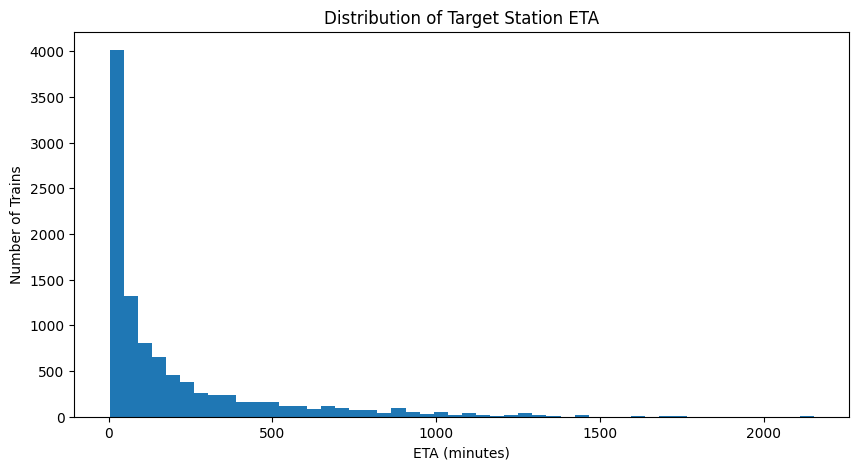

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(y, bins=50)

plt.xlabel("ETA (minutes)")
plt.ylabel("Number of Trains")
plt.title("Distribution of Target Station ETA")

plt.show()

In [80]:
print(y.describe())

count    10000.000000
mean       192.533650
std        275.733589
min          3.000000
25%          8.900000
50%         76.300000
75%        242.675000
max       2154.300000
Name: target_station_eta_minutes, dtype: float64


In [81]:
Q1 = y.quantile(0.25)
Q3 = y.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = y[(y < lower_bound) | (y > upper_bound)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Outlier percentage:", (len(outliers) / len(y)) * 100)

Q1: 8.9
Q3: 242.675
IQR: 233.775
Lower bound: -341.76250000000005
Upper bound: 593.3375000000001
Number of outliers: 956
Outlier percentage: 9.56


In [82]:


correlation = df[numeric_cols].corrwith(y)


correlation = correlation.sort_values(ascending=False)

print(correlation.head(15))

scheduled_remaining_travel_time_minutes           0.928119
segment_historical_average_travel_time_minutes    0.862690
remaining_distance_km                             0.773166
distance_current_to_target_km                     0.773166
current_distance_to_target_km                     0.773166
scheduled_segment_travel_time_minutes             0.491938
remaining_station_count                           0.488862
minutes_since_previous_station_departure          0.457289
total_route_distance_km                           0.443952
distance_previous_to_current_km                   0.427233
current_station_route_count                       0.380089
source_station_longitude                          0.296309
current_station_longitude                         0.291434
previous_station_longitude                        0.274041
current_station_is_junction                       0.263574
dtype: float64


In [83]:


suspicious_columns = [
    col for col in X.columns
    if "actual" in col.lower()
    or "eta" in col.lower()
    or "arrival_delay" in col.lower()
]

print("Potential leakage columns:")
print(suspicious_columns)

Potential leakage columns:
['previous_station_actual_arrival_date', 'previous_station_actual_arrival_time', 'previous_station_arrival_delay_minutes', 'previous_station_actual_departure_date', 'previous_station_actual_departure_time', 'previous_station_actual_halt_duration_minutes', 'target_station_actual_arrival_date', 'target_station_actual_arrival_time', 'target_station_arrival_delay_minutes']


In [84]:
print(df["journey_date"].head())
print(df["current_time"].head())
print(df["previous_station_actual_arrival_time"].head())

0      9/4/2025
1      9/3/2026
2     11/2/2025
3     5/22/2026
4    10/27/2026
Name: journey_date, dtype: str
0    13:34:42
1     5:09:54
2    14:05:51
3    21:29:15
4     4:18:24
Name: current_time, dtype: str
0    10:00:00
1     4:30:00
2     3:54:15
3    16:28:33
4     2:21:30
Name: previous_station_actual_arrival_time, dtype: str


In [85]:

df_fe = df.copy()


df_fe["journey_date"] = pd.to_datetime(
    df_fe["journey_date"],
    errors="coerce"
)

df_fe["journey_day"] = df_fe["journey_date"].dt.day
df_fe["journey_month"] = df_fe["journey_date"].dt.month
df_fe["journey_dayofweek"] = df_fe["journey_date"].dt.dayofweek


df_fe["is_weekend_new"] = (
    df_fe["journey_dayofweek"] >= 5
).astype(int)



current_time = pd.to_datetime(
    df_fe["current_time"],
    format="%H:%M:%S",
    errors="coerce"
)

df_fe["current_hour_new"] = current_time.dt.hour
df_fe["current_minute"] = current_time.dt.minute


df_fe["current_minutes_since_midnight"] = (
    current_time.dt.hour * 60
    + current_time.dt.minute
)



df_fe["is_peak_hour"] = (
    df_fe["current_hour_new"].between(7, 10)
    | df_fe["current_hour_new"].between(17, 20)
).astype(int)


print(df_fe[
    [
        "journey_date",
        "journey_day",
        "journey_month",
        "journey_dayofweek",
        "current_hour_new",
        "current_minute",
        "current_minutes_since_midnight",
        "is_peak_hour"
    ]
].head())

  journey_date  journey_day  journey_month  journey_dayofweek  \
0   2025-09-04            4              9                  3   
1   2026-09-03            3              9                  3   
2   2025-11-02            2             11                  6   
3   2026-05-22           22              5                  4   
4   2026-10-27           27             10                  1   

   current_hour_new  current_minute  current_minutes_since_midnight  \
0                13              34                             814   
1                 5               9                             309   
2                14               5                             845   
3                21              29                            1289   
4                 4              18                             258   

   is_peak_hour  
0             0  
1             0  
2             0  
3             0  
4             0  


In [86]:


df_fe["estimated_travel_time_from_speed"] = (
    df_fe["remaining_distance_km"] /
    df_fe["current_train_speed_kmph"].replace(0, float("nan"))
) * 60

df_fe["speed_distance_ratio"] = (
    df_fe["current_train_speed_kmph"] /
    df_fe["remaining_distance_km"].replace(0, float("nan"))
)


df_fe["delay_ratio"] = (
    df_fe["current_train_delay_minutes"] /
    df_fe["scheduled_remaining_travel_time_minutes"].replace(0, float("nan"))
)

print(df_fe[
    [
        "remaining_distance_km",
        "current_train_speed_kmph",
        "current_train_delay_minutes",
        "scheduled_remaining_travel_time_minutes",
        "estimated_travel_time_from_speed",
        "speed_distance_ratio",
        "delay_ratio"
    ]
].head())

   remaining_distance_km  current_train_speed_kmph  \
0                 603.82                      68.5   
1                 243.93                      88.5   
2                 384.46                      48.5   
3                 558.57                      71.6   
4                 118.77                      72.0   

   current_train_delay_minutes  scheduled_remaining_travel_time_minutes  \
0                          4.8                                    581.8   
1                         13.1                                    185.5   
2                          5.8                                    720.2   
3                         -3.8                                    487.1   
4                        -10.0                                     96.9   

   estimated_travel_time_from_speed  speed_distance_ratio  delay_ratio  
0                        528.893431              0.113444     0.008250  
1                        165.376271              0.362809     0.070620  
2    

In [87]:


df_fe["delay_per_station"] = (
    df_fe["current_train_delay_minutes"] /
    df_fe["remaining_station_count"].replace(0, float("nan"))
)

df_fe["delay_change_ratio"] = (
    df_fe["delay_change_from_previous_station_minutes"] /
    (df_fe["current_train_delay_minutes"].abs() + 1)
)


df_fe["speed_change_5_to_30"] = (
    df_fe["average_speed_last_5_minutes_kmph"]
    - df_fe["average_speed_last_30_minutes_kmph"]
)


df_fe["average_recent_speed"] = (
    df_fe[
        [
            "average_speed_last_5_minutes_kmph",
            "average_speed_last_10_minutes_kmph",
            "average_speed_last_30_minutes_kmph"
        ]
    ].mean(axis=1)
)

print(df_fe[
    [
        "current_train_delay_minutes",
        "remaining_station_count",
        "delay_per_station",
        "delay_change_from_previous_station_minutes",
        "delay_change_ratio",
        "speed_change_5_to_30",
        "average_recent_speed"
    ]
].head())

   current_train_delay_minutes  remaining_station_count  delay_per_station  \
0                          4.8                       10           0.480000   
1                         13.1                        2           6.550000   
2                          5.8                        5           1.160000   
3                         -3.8                        6          -0.633333   
4                        -10.0                        1         -10.000000   

   delay_change_from_previous_station_minutes  delay_change_ratio  \
0                                        -2.4           -0.413793   
1                                         5.8            0.411348   
2                                         2.3            0.338235   
3                                        -7.6           -1.583333   
4                                        -4.1           -0.372727   

   speed_change_5_to_30  average_recent_speed  
0                 -12.4             68.433333  
1                  -

In [88]:
risk_cols = [
    "rainfall_mm",
    "fog_level",
    "waterlogging_risk",
    "visibility_km",
    "station_congestion_level",
    "signal_delay_risk",
    "speed_restriction_active",
    "crew_change_delay_risk"
]

print(df_fe[risk_cols].dtypes)

rainfall_mm                 float64
fog_level                       str
waterlogging_risk               str
visibility_km               float64
station_congestion_level        str
signal_delay_risk               str
speed_restriction_active      int64
crew_change_delay_risk          str
dtype: object


In [89]:
categorical_risk_cols = [
    "fog_level",
    "waterlogging_risk",
    "station_congestion_level",
    "signal_delay_risk",
    "crew_change_delay_risk"
]

for col in categorical_risk_cols:
    print("\n", col)
    print(df_fe[col].value_counts())


 fog_level
fog_level
No Fog    9142
Low        648
Medium     149
High        61
Name: count, dtype: int64

 waterlogging_risk
waterlogging_risk
Low       9497
Medium     451
High        52
Name: count, dtype: int64

 station_congestion_level
station_congestion_level
Medium    3897
Low       3437
High      2666
Name: count, dtype: int64

 signal_delay_risk
signal_delay_risk
Low       5060
Medium    3143
High      1797
Name: count, dtype: int64

 crew_change_delay_risk
crew_change_delay_risk
Low       6928
Medium    2459
High       613
Name: count, dtype: int64


In [90]:


risk_mapping = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

# Fog
df_fe["fog_level_encoded"] = (
    df_fe["fog_level"]
    .map({"No Fog": 0, "Low": 1, "Medium": 2, "High": 3})
)

# Waterlogging
df_fe["waterlogging_risk_encoded"] = (
    df_fe["waterlogging_risk"].map(risk_mapping)
)

# Station congestion
df_fe["station_congestion_encoded"] = (
    df_fe["station_congestion_level"].map(risk_mapping)
)

# Signal delay risk
df_fe["signal_delay_encoded"] = (
    df_fe["signal_delay_risk"].map(risk_mapping)
)

# Crew change delay risk
df_fe["crew_change_delay_encoded"] = (
    df_fe["crew_change_delay_risk"].map(risk_mapping)
)

print(df_fe[
    [
        "fog_level",
        "fog_level_encoded",
        "waterlogging_risk",
        "waterlogging_risk_encoded",
        "station_congestion_level",
        "station_congestion_encoded",
        "signal_delay_risk",
        "signal_delay_encoded",
        "crew_change_delay_risk",
        "crew_change_delay_encoded"
    ]
].head())

  fog_level  fog_level_encoded waterlogging_risk  waterlogging_risk_encoded  \
0    No Fog                  0               Low                          1   
1    No Fog                  0               Low                          1   
2    No Fog                  0               Low                          1   
3    No Fog                  0               Low                          1   
4       Low                  1               Low                          1   

  station_congestion_level  station_congestion_encoded signal_delay_risk  \
0                     High                           3               Low   
1                      Low                           1            Medium   
2                      Low                           1            Medium   
3                      Low                           1            Medium   
4                     High                           3               Low   

   signal_delay_encoded crew_change_delay_risk  crew_change_delay_en

In [91]:
# Environmental risk
df_fe["environmental_risk"] = (
    df_fe["fog_level_encoded"]
    + df_fe["waterlogging_risk_encoded"]
    + df_fe["rainfall_mm"].fillna(0)
)

# Operational risk
df_fe["operational_risk"] = (
    df_fe["station_congestion_encoded"]
    + df_fe["signal_delay_encoded"]
    + df_fe["crew_change_delay_encoded"]
    + df_fe["speed_restriction_active"]
)

print(df_fe[
    [
        "environmental_risk",
        "operational_risk"
    ]
].head())

   environmental_risk  operational_risk
0                 2.1                 6
1                 1.4                 4
2                 1.0                 4
3                 1.0                 5
4                 2.0                 6


In [92]:
# Missing values check
print("Missing values:")
print(df_fe.isnull().sum()[df_fe.isnull().sum() > 0])

# Infinite values check
print("\nInfinite values:")
print(np.isinf(df_fe.select_dtypes(include=np.number)).sum().sum())

Missing values:
Series([], dtype: int64)

Infinite values:
0


In [93]:
missing=df_fe.isnull().sum()
print(missing[missing>0])

Series([], dtype: int64)


In [94]:
leakage_cols = [
    "target_station_actual_arrival_date",
    "target_station_actual_arrival_time",
    "target_station_arrival_delay_minutes"
]

df_model = df_fe.drop(columns=leakage_cols)

print("Shape before:", df_fe.shape)
print("Shape after :", df_model.shape)

Shape before: (10000, 140)
Shape after : (10000, 137)


In [95]:
# Target
y = df_model["target_station_eta_minutes"]

# Features
X = df_model.drop(columns=["target_station_eta_minutes"])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 136)
y shape: (10000,)


In [96]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (8000, 136)
X_test : (2000, 136)
y_train: (8000,)
y_test : (2000,)


In [97]:
# Numerical columns
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()

# Categorical columns
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Number of numerical columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

print("\nCategorical columns:")
print(categorical_cols)

Number of numerical columns: 90
Number of categorical columns: 46

Categorical columns:
['train_name', 'train_type', 'train_category', 'railway_zone', 'train_priority', 'journey_date', 'day_of_week', 'journey_start_time', 'current_time', 'source_station_code', 'source_station_name', 'destination_station_code', 'destination_station_name', 'previous_station_code', 'previous_station_name', 'current_station_code', 'current_station_name', 'target_station_code', 'target_station_name', 'current_station_railway_zone', 'target_station_railway_zone', 'previous_station_scheduled_arrival_date', 'previous_station_scheduled_arrival_time', 'previous_station_scheduled_departure_date', 'previous_station_scheduled_departure_time', 'current_station_scheduled_arrival_date', 'current_station_scheduled_arrival_time', 'current_station_scheduled_departure_date', 'current_station_scheduled_departure_time', 'target_station_scheduled_arrival_date', 'target_station_scheduled_arrival_time', 'target_station_schedul

In [98]:
# Categorical columns ko check karna
for col in categorical_cols:
    print("\n", col)
    print(X_train[col].nunique(), "unique values")


 train_name
24 unique values

 train_type
7 unique values

 train_category
5 unique values

 railway_zone
5 unique values

 train_priority
3 unique values

 journey_date
487 unique values

 day_of_week
7 unique values

 journey_start_time
33 unique values

 current_time
7396 unique values

 source_station_code
5 unique values

 source_station_name
5 unique values

 destination_station_code
7 unique values

 destination_station_name
7 unique values

 previous_station_code
30 unique values

 previous_station_name
30 unique values

 current_station_code
30 unique values

 current_station_name
30 unique values

 target_station_code
30 unique values

 target_station_name
30 unique values

 current_station_railway_zone
12 unique values

 target_station_railway_zone
11 unique values

 previous_station_scheduled_arrival_date
488 unique values

 previous_station_scheduled_arrival_time
185 unique values

 previous_station_scheduled_departure_date
488 unique values

 previous_station_scheduled_d

In [99]:
# Raw date/time columns
datetime_cols = [
    "journey_date",
    "journey_start_time",
    "current_time",

    "previous_station_scheduled_arrival_date",
    "previous_station_scheduled_arrival_time",
    "previous_station_scheduled_departure_date",
    "previous_station_scheduled_departure_time",

    "current_station_scheduled_arrival_date",
    "current_station_scheduled_arrival_time",
    "current_station_scheduled_departure_date",
    "current_station_scheduled_departure_time",

    "target_station_scheduled_arrival_date",
    "target_station_scheduled_arrival_time",
    "target_station_scheduled_departure_date",
    "target_station_scheduled_departure_time"
]

# Sirf wahi columns remove hon jo dataset me actually present hain
datetime_cols = [col for col in datetime_cols if col in X_train.columns]

X_train_clean = X_train.drop(columns=datetime_cols)
X_test_clean = X_test.drop(columns=datetime_cols)

print("Removed datetime columns:", datetime_cols)
print("X_train shape:", X_train_clean.shape)
print("X_test shape:", X_test_clean.shape)

Removed datetime columns: ['journey_date', 'journey_start_time', 'current_time', 'previous_station_scheduled_arrival_date', 'previous_station_scheduled_arrival_time', 'previous_station_scheduled_departure_date', 'previous_station_scheduled_departure_time', 'current_station_scheduled_arrival_date', 'current_station_scheduled_arrival_time', 'current_station_scheduled_departure_date', 'current_station_scheduled_departure_time', 'target_station_scheduled_arrival_date', 'target_station_scheduled_arrival_time', 'target_station_scheduled_departure_date', 'target_station_scheduled_departure_time']
X_train shape: (8000, 121)
X_test shape: (2000, 121)


In [100]:
from sklearn.preprocessing import OneHotEncoder

# Categorical columns dobara identify karo
categorical_cols_clean = X_train_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Categorical columns:", len(categorical_cols_clean))
print(categorical_cols_clean)

Categorical columns: 31
['train_name', 'train_type', 'train_category', 'railway_zone', 'train_priority', 'day_of_week', 'source_station_code', 'source_station_name', 'destination_station_code', 'destination_station_name', 'previous_station_code', 'previous_station_name', 'current_station_code', 'current_station_name', 'target_station_code', 'target_station_name', 'current_station_railway_zone', 'target_station_railway_zone', 'previous_station_actual_arrival_date', 'previous_station_actual_arrival_time', 'previous_station_actual_departure_date', 'previous_station_actual_departure_time', 'delay_trend', 'section_congestion_level', 'signal_delay_risk', 'station_congestion_level', 'freight_train_density', 'fog_level', 'waterlogging_risk', 'weather_condition', 'crew_change_delay_risk']


In [101]:
# Raw previous-station actual date/time columns
previous_actual_datetime_cols = [
    "previous_station_actual_arrival_date",
    "previous_station_actual_arrival_time",
    "previous_station_actual_departure_date",
    "previous_station_actual_departure_time"
]

# Remove from train and test
X_train_ready = X_train_clean.drop(
    columns=previous_actual_datetime_cols,
    errors="ignore"
)

X_test_ready = X_test_clean.drop(
    columns=previous_actual_datetime_cols,
    errors="ignore"
)

# New categorical columns
categorical_cols_ready = X_train_ready.select_dtypes(
    exclude=np.number
).columns.tolist()

print("X_train shape:", X_train_ready.shape)
print("X_test shape:", X_test_ready.shape)

print("Categorical columns:", len(categorical_cols_ready))
print(categorical_cols_ready)

X_train shape: (8000, 117)
X_test shape: (2000, 117)
Categorical columns: 27
['train_name', 'train_type', 'train_category', 'railway_zone', 'train_priority', 'day_of_week', 'source_station_code', 'source_station_name', 'destination_station_code', 'destination_station_name', 'previous_station_code', 'previous_station_name', 'current_station_code', 'current_station_name', 'target_station_code', 'target_station_name', 'current_station_railway_zone', 'target_station_railway_zone', 'delay_trend', 'section_congestion_level', 'signal_delay_risk', 'station_congestion_level', 'freight_train_density', 'fog_level', 'waterlogging_risk', 'weather_condition', 'crew_change_delay_risk']


In [102]:
from sklearn.preprocessing import OneHotEncoder

# One Hot Encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit only on training data
X_train_cat = encoder.fit_transform(
    X_train_ready[categorical_cols_ready]
)

# Transform test data using same encoder
X_test_cat = encoder.transform(
    X_test_ready[categorical_cols_ready]
)

print("Encoded X_train categorical shape:", X_train_cat.shape)
print("Encoded X_test categorical shape:", X_test_cat.shape)

Encoded X_train categorical shape: (8000, 309)
Encoded X_test categorical shape: (2000, 309)


In [103]:
# Numerical columns
numeric_cols_ready = X_train_ready.select_dtypes(
    include=np.number
).columns.tolist()

# Numerical data
X_train_num = X_train_ready[numeric_cols_ready].to_numpy()
X_test_num = X_test_ready[numeric_cols_ready].to_numpy()

print("Numerical X_train shape:", X_train_num.shape)
print("Numerical X_test shape:", X_test_num.shape)

# Combine numerical + encoded categorical
X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

print("Final X_train shape:", X_train_final.shape)
print("Final X_test shape:", X_test_final.shape)

Numerical X_train shape: (8000, 90)
Numerical X_test shape: (2000, 90)
Final X_train shape: (8000, 399)
Final X_test shape: (2000, 399)


In [104]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_final, y_train)



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [105]:
y_pred = model.predict(X_test_final)

print("Predictions:", y_pred[:10])

Predictions: [145.1935 116.5675 131.3575  56.636   70.0065 126.463   32.398   47.1735
  31.697  782.857 ]


In [106]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 15.11926275000001
RMSE: 24.713329811391777
R2 Score: 0.9924670456608881


In [107]:

importance = model.feature_importances_

print("Number of feature importances:", len(importance))

Number of feature importances: 399


In [108]:
import pandas as pd

# Encoded categorical feature names
encoded_feature_names = encoder.get_feature_names_out(
    categorical_cols_ready
)

# All feature names
all_feature_names = numeric_cols_ready + list(encoded_feature_names)

# Feature importance dataframe
feature_importance_df = pd.DataFrame({
    "feature": all_feature_names,
    "importance": model.feature_importances_
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
)

# Top 20
print(feature_importance_df.head(20))

                                             feature  importance
34           scheduled_remaining_travel_time_minutes    0.848306
33             scheduled_segment_travel_time_minutes    0.032424
39                     current_distance_to_target_km    0.023036
28                     distance_current_to_target_km    0.022817
29                             remaining_distance_km    0.022528
17                           current_train_longitude    0.009817
40          minutes_since_previous_station_departure    0.007270
58                          speed_restriction_active    0.003410
51               train_historical_average_speed_kmph    0.002348
59                      speed_restriction_level_kmph    0.002105
38                average_speed_last_30_minutes_kmph    0.001794
53  station_historical_average_halt_duration_minutes    0.001726
27                   distance_previous_to_current_km    0.001164
16                            current_train_latitude    0.000933
77                       

In [109]:
print("Target statistics:")
print(y_train.describe())

print("\nScheduled remaining travel time:")
print(X_train["scheduled_remaining_travel_time_minutes"].describe())

print("\nCorrelation with target:")
print(
    np.corrcoef(
        X_train["scheduled_remaining_travel_time_minutes"],
        y_train
    )[0, 1]
)

Target statistics:
count    8000.000000
mean      191.106412
std       273.416703
min         3.000000
25%         8.900000
50%        75.600000
75%       240.150000
max      2135.800000
Name: target_station_eta_minutes, dtype: float64

Scheduled remaining travel time:
count    8000.000000
mean      337.644325
std       330.187939
min        10.700000
25%        94.500000
50%       208.700000
75%       459.400000
max      1928.500000
Name: scheduled_remaining_travel_time_minutes, dtype: float64

Correlation with target:
0.9272614136950634


In [110]:
# Remove highly correlated feature
X_train_reduced = X_train_final.copy()
X_test_reduced = X_test_final.copy()

# Feature index find karo
feature_names = (
    numeric_cols_ready +
    list(encoder.get_feature_names_out(categorical_cols_ready))
)

idx = feature_names.index("scheduled_remaining_travel_time_minutes")

# Remove the feature
X_train_reduced = np.delete(X_train_reduced, idx, axis=1)
X_test_reduced = np.delete(X_test_reduced, idx, axis=1)

print("Before:", X_train_final.shape)
print("After :", X_train_reduced.shape)

Before: (8000, 399)
After : (8000, 398)


In [111]:
from sklearn.ensemble import RandomForestRegressor

model_reduced = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model_reduced.fit(X_train_reduced, y_train)

y_pred_reduced = model_reduced.predict(X_test_reduced)

In [112]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_reduced)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_reduced))
r2 = r2_score(y_test, y_pred_reduced)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 17.510764500000008
RMSE: 29.16793734489552
R2 Score: 0.9895066479976974


In [113]:
# Feature importance of reduced model

importance_reduced = model_reduced.feature_importances_

# Remove the deleted feature from feature names
feature_names_reduced = [
    name for i, name in enumerate(feature_names)
    if i != idx
]

feature_importance_reduced_df = pd.DataFrame({
    "feature": feature_names_reduced,
    "importance": importance_reduced
})

feature_importance_reduced_df = (
    feature_importance_reduced_df
    .sort_values(by="importance", ascending=False)
)

print(feature_importance_reduced_df.head(20))

                                              feature  importance
53     segment_historical_average_travel_time_minutes    0.720528
33              scheduled_segment_travel_time_minutes    0.058022
50                train_historical_average_speed_kmph    0.055577
29                              remaining_distance_km    0.030394
38                      current_distance_to_target_km    0.029570
28                      distance_current_to_target_km    0.029385
0                                        train_number    0.004390
39           minutes_since_previous_station_departure    0.004241
48             train_historical_average_delay_minutes    0.003959
49                train_historical_on_time_percentage    0.003617
52   station_historical_average_halt_duration_minutes    0.003074
54       segment_historical_delay_variability_minutes    0.003022
37                 average_speed_last_30_minutes_kmph    0.002814
57                           speed_restriction_active    0.002637
51        

In [114]:
# Check relationship of top features with target

check_cols = [
    "segment_historical_average_travel_time_minutes",
    "scheduled_segment_travel_time_minutes",
    "train_historical_average_speed_kmph",
    "remaining_distance_km",
    "current_distance_to_target_km"
]

for col in check_cols:
    if col in X_train.columns:
        corr = np.corrcoef(X_train[col], y_train)[0, 1]
        print(col, ":", corr)

segment_historical_average_travel_time_minutes : 0.8641258921273048
scheduled_segment_travel_time_minutes : 0.49983049179504146
train_historical_average_speed_kmph : -0.19522622978322002
remaining_distance_km : 0.7736455705765302
current_distance_to_target_km : 0.7736455705765302


In [115]:
# Check possible target-derived features

possible_features = [
    "segment_historical_average_travel_time_minutes",
    "scheduled_segment_travel_time_minutes",
    "remaining_distance_km",
    "current_distance_to_target_km",
    "train_historical_average_delay_minutes",
    "station_historical_average_delay_minutes",
    "train_historical_on_time_percentage"
]

for col in possible_features:
    if col in df_fe.columns:
        print(col, "exists")

segment_historical_average_travel_time_minutes exists
scheduled_segment_travel_time_minutes exists
remaining_distance_km exists
current_distance_to_target_km exists
train_historical_average_delay_minutes exists
station_historical_average_delay_minutes exists
train_historical_on_time_percentage exists


In [116]:
cols_to_check = [
    "target_station_eta_minutes",
    "segment_historical_average_travel_time_minutes",
    "scheduled_segment_travel_time_minutes",
    "remaining_distance_km",
    "current_distance_to_target_km",
    "train_historical_average_delay_minutes",
    "station_historical_average_delay_minutes",
    "train_historical_on_time_percentage"
]

print(df_fe[cols_to_check].head(10))

   target_station_eta_minutes  segment_historical_average_travel_time_minutes  \
0                       501.8                                           663.3   
1                       186.2                                           274.7   
2                       316.9                                          1028.0   
3                       445.2                                           651.3   
4                        80.8                                           146.4   
5                        96.0                                            75.9   
6                        45.7                                           260.4   
7                       135.2                                           551.8   
8                       329.8                                           639.3   
9                       550.7                                           572.9   

   scheduled_segment_travel_time_minutes  remaining_distance_km  \
0                                  123.5 

In [117]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_reduced, y_train)

y_pred_xgb = xgb_model.predict(X_test_reduced)

print(y_pred_xgb[:10])

[141.11833  122.10175  112.49058   63.862267  78.301994 131.6011
  29.799213  41.813778  31.39664  783.1148  ]


In [118]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost MAE :", mae_xgb)
print("XGBoost RMSE:", rmse_xgb)
print("XGBoost R2  :", r2_xgb)

XGBoost MAE : 13.073546700342744
XGBoost RMSE: 19.88978367302888
XGBoost R2  : 0.9951206392981193


In [119]:
# Check target leakage candidates

leakage_cols = [
    "scheduled_remaining_travel_time_minutes",
    "target_station_eta_minutes",
    "target_station_actual_arrival_date",
    "target_station_actual_arrival_time"
]

for col in leakage_cols:
    if col in df_fe.columns:
        print(col, "EXISTS")

scheduled_remaining_travel_time_minutes EXISTS
target_station_eta_minutes EXISTS
target_station_actual_arrival_date EXISTS
target_station_actual_arrival_time EXISTS


In [120]:
# Check important features for possible data leakage

cols = [
    "scheduled_remaining_travel_time_minutes",
    "target_station_actual_arrival_date",
    "target_station_actual_arrival_time"
]

for col in cols:
    if col in df_fe.columns:
        print("\n", col)
        print(df_fe[col].head())
        print("Missing:", df_fe[col].isna().sum())


 scheduled_remaining_travel_time_minutes
0    581.8
1    185.5
2    720.2
3    487.1
4     96.9
Name: scheduled_remaining_travel_time_minutes, dtype: float64
Missing: 0

 target_station_actual_arrival_date
0      9/4/2025
1      9/3/2026
2     11/3/2025
3     5/23/2026
4    10/27/2026
Name: target_station_actual_arrival_date, dtype: str
Missing: 0

 target_station_actual_arrival_time
0    21:56:29
1     8:16:05
2    19:22:46
3     4:54:30
4     5:39:10
Name: target_station_actual_arrival_time, dtype: str
Missing: 0


In [121]:
# Check relationship between target and scheduled remaining travel time

print("Correlation:")
print(
    df_fe[
        ["target_station_eta_minutes",
         "scheduled_remaining_travel_time_minutes"]
    ].corr()
)

print("\nSample comparison:")
print(
    df_fe[
        ["target_station_eta_minutes",
         "scheduled_remaining_travel_time_minutes"]
    ].head(20)
)

Correlation:
                                         target_station_eta_minutes  \
target_station_eta_minutes                                 1.000000   
scheduled_remaining_travel_time_minutes                    0.928119   

                                         scheduled_remaining_travel_time_minutes  
target_station_eta_minutes                                              0.928119  
scheduled_remaining_travel_time_minutes                                 1.000000  

Sample comparison:
    target_station_eta_minutes  scheduled_remaining_travel_time_minutes
0                        501.8                                    581.8
1                        186.2                                    185.5
2                        316.9                                    720.2
3                        445.2                                    487.1
4                         80.8                                     96.9
5                         96.0                                     93.3


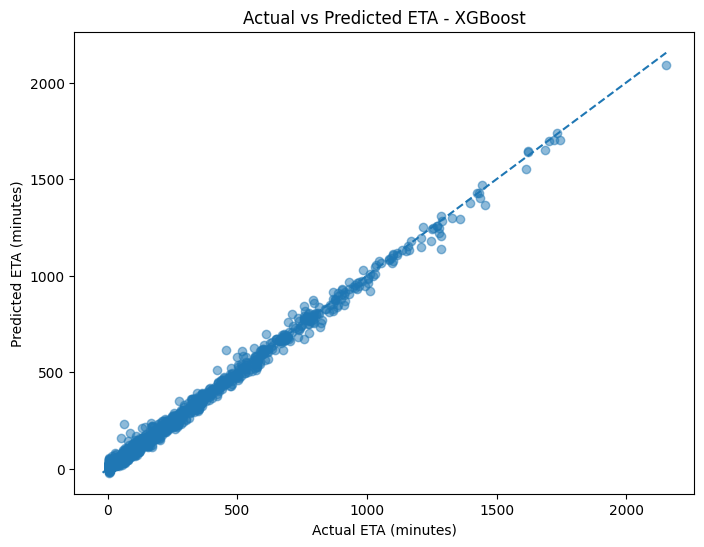

In [122]:
import matplotlib.pyplot as plt

# Actual vs Predicted
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_xgb, alpha=0.5)

plt.xlabel("Actual ETA (minutes)")
plt.ylabel("Predicted ETA (minutes)")
plt.title("Actual vs Predicted ETA - XGBoost")

# Perfect prediction line
min_val = min(y_test.min(), y_pred_xgb.min())
max_val = max(y_test.max(), y_pred_xgb.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.show()

In [123]:
import pandas as pd
import numpy as np

# Prediction errors
error_df = pd.DataFrame({
    "Actual_ETA": y_test.values,
    "Predicted_ETA": y_pred_xgb
})

error_df["Error"] = error_df["Predicted_ETA"] - error_df["Actual_ETA"]
error_df["Absolute_Error"] = abs(error_df["Error"])

print("Mean Absolute Error:",
      error_df["Absolute_Error"].mean())

print("\nMaximum Error:",
      error_df["Absolute_Error"].max())

print("\n90th Percentile Error:",
      error_df["Absolute_Error"].quantile(0.90))

print("\nWorst 10 predictions:")
print(
    error_df.sort_values(
        by="Absolute_Error",
        ascending=False
    ).head(10)
)

Mean Absolute Error: 13.073546700342744

Maximum Error: 172.39074096679687

90th Percentile Error: 30.17683746337891

Worst 10 predictions:
      Actual_ETA  Predicted_ETA       Error  Absolute_Error
651         61.9     234.290741  172.390741      172.390741
1533       455.6     613.207947  157.607947      157.607947
1015      1285.7    1135.970093 -149.729907      149.729907
1605        51.8     158.350021  106.550021      106.550021
124         87.2     186.974792   99.774792       99.774792
1257      1010.8     918.060608  -92.739392       92.739392
694        516.6     608.621094   92.021094       92.021094
427        420.7     512.433167   91.733167       91.733167
1832      1454.9    1366.276245  -88.623755       88.623755
1024       710.9     798.809082   87.909082       87.909082


In [124]:
# Check whether scheduled remaining travel time is almost
# directly related to ETA

df_check = df_fe[
    [
        "target_station_eta_minutes",
        "scheduled_remaining_travel_time_minutes"
    ]
].copy()

df_check["difference"] = (
    df_check["target_station_eta_minutes"]
    - df_check["scheduled_remaining_travel_time_minutes"]
)

print(df_check["difference"].describe())

print("\nCorrelation:",
      df_check[
          [
              "target_station_eta_minutes",
              "scheduled_remaining_travel_time_minutes"
          ]
      ].corr().iloc[0, 1])

count    10000.000000
mean      -147.312240
std        128.116372
min       -556.500000
25%       -214.600000
50%       -111.200000
75%        -50.800000
max        225.800000
Name: difference, dtype: float64

Correlation: 0.9281193823161444


In [125]:
# Check whether feature names for the reduced dataset are available

print([
    name for name in globals()
    if "feature" in name.lower() and "name" in name.lower()
])

['encoded_feature_names', 'all_feature_names', 'feature_names', 'feature_names_reduced']


In [126]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# XGBoost model
xgb_model_final = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model_final.fit(X_train_reduced, y_train)

# Prediction
y_pred_final = xgb_model_final.predict(X_test_reduced)

# Evaluation
mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

print("Final XGBoost MAE :", mae_final)
print("Final XGBoost RMSE:", rmse_final)
print("Final XGBoost R2  :", r2_final)

Final XGBoost MAE : 13.073546700342744
Final XGBoost RMSE: 19.88978367302888
Final XGBoost R2  : 0.9951206392981193


In [127]:
# Error analysis

error_df = pd.DataFrame({
    "Actual_ETA": y_test,
    "Predicted_ETA": y_pred_final
})

error_df["Error"] = (
    error_df["Predicted_ETA"] - error_df["Actual_ETA"]
)

error_df["Absolute_Error"] = error_df["Error"].abs()

print("Mean Absolute Error:",
      error_df["Absolute_Error"].mean())

print("\nMaximum Error:",
      error_df["Absolute_Error"].max())

print("\n90th Percentile Error:",
      error_df["Absolute_Error"].quantile(0.90))

print("\nWorst 10 Predictions:")
print(
    error_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

Mean Absolute Error: 13.073546700342744

Maximum Error: 172.39074096679687

90th Percentile Error: 30.17683746337891

Worst 10 Predictions:
      Actual_ETA  Predicted_ETA       Error  Absolute_Error
8069        61.9     234.290741  172.390741      172.390741
1162       455.6     613.207947  157.607947      157.607947
9784      1285.7    1135.970093 -149.729907      149.729907
4623        51.8     158.350021  106.550021      106.550021
3350        87.2     186.974792   99.774792       99.774792
9525      1010.8     918.060608  -92.739392       92.739392
9547       516.6     608.621094   92.021094       92.021094
500        420.7     512.433167   91.733167       91.733167
3520      1454.9    1366.276245  -88.623755       88.623755
9186       710.9     798.809082   87.909082       87.909082


In [128]:
# Investigate worst prediction cases

worst_indices = (
    error_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .index
)

cols_to_show = [
    "target_station_eta_minutes",
    "scheduled_remaining_travel_time_minutes",
    "remaining_distance_km",
    "current_distance_to_target_km",
    "segment_historical_average_travel_time_minutes",
    "scheduled_segment_travel_time_minutes",
    "train_historical_average_speed_kmph",
    "train_historical_average_delay_minutes",
    "station_historical_average_delay_minutes",
    "average_speed_last_30_minutes_kmph",
    "speed_restriction_active"
]

available_cols = [c for c in cols_to_show if c in df_fe.columns]

print(df_fe.loc[worst_indices, available_cols])

      target_station_eta_minutes  scheduled_remaining_travel_time_minutes  \
8069                        61.9                                    394.2   
1162                       455.6                                    968.0   
9784                      1285.7                                   1331.9   
4623                        51.8                                    490.7   
3350                        87.2                                    571.7   
9525                      1010.8                                   1125.3   
9547                       516.6                                    840.3   
500                        420.7                                    670.4   
3520                      1454.9                                   1537.0   
9186                       710.9                                   1155.4   

      remaining_distance_km  current_distance_to_target_km  \
8069                 202.62                         202.62   
1162                 834.48 

In [129]:
# Baseline: use scheduled remaining travel time directly as ETA

baseline_pred = df_fe.loc[y_test.index, "scheduled_remaining_travel_time_minutes"]

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("Scheduled Time Baseline")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2  :", baseline_r2)

Scheduled Time Baseline
MAE : 152.79864999999998
RMSE: 198.12639343358572
R2  : 0.5158415981552997


In [130]:
# Check journey date range

print("Minimum date:", df_fe["journey_date"].min())
print("Maximum date:", df_fe["journey_date"].max())

Minimum date: 2025-09-01 00:00:00
Maximum date: 2026-12-31 00:00:00


In [131]:
# Sort data by journey date
df_time = df_fe.sort_values("journey_date").reset_index(drop=True)

# 80% past data for training, 20% future data for testing
split_index = int(len(df_time) * 0.80)

train_time = df_time.iloc[:split_index]
test_time = df_time.iloc[split_index:]

print("Training data:")
print(train_time["journey_date"].min())
print(train_time["journey_date"].max())

print("\nTesting data:")
print(test_time["journey_date"].min())
print(test_time["journey_date"].max())

print("\nTrain rows:", len(train_time))
print("Test rows:", len(test_time))

Training data:
2025-09-01 00:00:00
2026-09-25 00:00:00

Testing data:
2026-09-25 00:00:00
2026-12-31 00:00:00

Train rows: 8000
Test rows: 2000


In [132]:
import numpy as np
from sklearn.preprocessing import OneHotEncoder

# Target
target_col = "target_station_eta_minutes"

# Columns that should NOT be used
drop_cols = [
    target_col,
    "target_station_actual_arrival_date",
    "target_station_actual_arrival_time",
    "target_station_arrival_delay_minutes",

    # Raw datetime columns
    "journey_date",
    "journey_start_time",
    "current_time",
    "previous_station_scheduled_arrival_date",
    "previous_station_scheduled_arrival_time",
    "previous_station_scheduled_departure_date",
    "previous_station_scheduled_departure_time",
    "current_station_scheduled_arrival_date",
    "current_station_scheduled_arrival_time",
    "current_station_scheduled_departure_date",
    "current_station_scheduled_departure_time",
    "target_station_scheduled_arrival_date",
    "target_station_scheduled_arrival_time",
    "target_station_scheduled_departure_date",
    "target_station_scheduled_departure_time",

    # Raw previous-station datetime columns
    "previous_station_actual_arrival_date",
    "previous_station_actual_arrival_time",
    "previous_station_actual_departure_date",
    "previous_station_actual_departure_time"
]

# Remove only columns that actually exist
drop_cols = [col for col in drop_cols if col in train_time.columns]

# X and y
X_train_time = train_time.drop(columns=drop_cols)
y_train_time = train_time[target_col]

X_test_time = test_time.drop(columns=drop_cols)
y_test_time = test_time[target_col]

print("X_train:", X_train_time.shape)
print("X_test :", X_test_time.shape)

X_train: (8000, 117)
X_test : (2000, 117)


In [133]:
# Numerical columns
numeric_cols_time = X_train_time.select_dtypes(include=np.number).columns.tolist()

# Categorical columns
categorical_cols_time = X_train_time.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", len(numeric_cols_time))
print("Categorical columns:", len(categorical_cols_time))

print("\nCategorical columns:")
print(categorical_cols_time)

Numerical columns: 90
Categorical columns: 27

Categorical columns:
['train_name', 'train_type', 'train_category', 'railway_zone', 'train_priority', 'day_of_week', 'source_station_code', 'source_station_name', 'destination_station_code', 'destination_station_name', 'previous_station_code', 'previous_station_name', 'current_station_code', 'current_station_name', 'target_station_code', 'target_station_name', 'current_station_railway_zone', 'target_station_railway_zone', 'delay_trend', 'section_congestion_level', 'signal_delay_risk', 'station_congestion_level', 'freight_train_density', 'fog_level', 'waterlogging_risk', 'weather_condition', 'crew_change_delay_risk']


C:\Users\SHANU KUSHWAHA\AppData\Local\Temp\ipykernel_15544\3965517919.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_time = X_train_time.select_dtypes(include="object").columns.tolist()


In [134]:
from sklearn.preprocessing import OneHotEncoder

# Encoder
encoder_time = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit ONLY on training data
X_train_cat_time = encoder_time.fit_transform(
    X_train_time[categorical_cols_time]
)

# Transform test data
X_test_cat_time = encoder_time.transform(
    X_test_time[categorical_cols_time]
)

print("Encoded train categorical shape:", X_train_cat_time.shape)
print("Encoded test categorical shape :", X_test_cat_time.shape)

Encoded train categorical shape: (8000, 309)
Encoded test categorical shape : (2000, 309)


In [135]:
# Numerical data
X_train_num_time = X_train_time[numeric_cols_time].to_numpy()
X_test_num_time = X_test_time[numeric_cols_time].to_numpy()

# Combine numerical + encoded categorical features
X_train_final_time = np.hstack([
    X_train_num_time,
    X_train_cat_time
])

X_test_final_time = np.hstack([
    X_test_num_time,
    X_test_cat_time
])

print("Final training shape:", X_train_final_time.shape)
print("Final testing shape :", X_test_final_time.shape)

Final training shape: (8000, 399)
Final testing shape : (2000, 399)


In [136]:
# Get encoded categorical feature names
encoded_feature_names_time = encoder_time.get_feature_names_out(
    categorical_cols_time
)

# Combine numerical + categorical feature names
feature_names_time = (
    numeric_cols_time +
    list(encoded_feature_names_time)
)

print("Total feature names:", len(feature_names_time))
print("First 20 features:")
print(feature_names_time[:20])

Total feature names: 399
First 20 features:
['train_number', 'is_special_train', 'is_weekend', 'current_hour', 'current_month', 'is_night_time', 'source_station_latitude', 'source_station_longitude', 'previous_station_latitude', 'previous_station_longitude', 'current_station_latitude', 'current_station_longitude', 'target_station_latitude', 'target_station_longitude', 'destination_station_latitude', 'destination_station_longitude', 'current_train_latitude', 'current_train_longitude', 'current_station_is_junction', 'current_station_route_count']


In [137]:
from xgboost import XGBRegressor

xgb_time = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train on past data
xgb_time.fit(
    X_train_final_time,
    y_train_time
)



,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [138]:
# Prediction on future test data
y_pred_time = xgb_time.predict(X_test_final_time)

print("Prediction completed!")
print("Number of predictions:", len(y_pred_time))

# First 10 predictions
print("\nFirst 10 predictions:")
print(y_pred_time[:10])

Prediction completed!
Number of predictions: 2000

First 10 predictions:
[ 12.672777 790.39984   93.276695  44.293232  29.669312  35.39873
  61.809345  21.694075 154.68974  387.8101  ]


In [139]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluation metrics
mae_time = mean_absolute_error(y_test_time, y_pred_time)
rmse_time = np.sqrt(mean_squared_error(y_test_time, y_pred_time))
r2_time = r2_score(y_test_time, y_pred_time)

print("Temporal XGBoost Results")
print("-------------------------")
print("MAE  :", mae_time)
print("RMSE :", rmse_time)
print("R²   :", r2_time)

Temporal XGBoost Results
-------------------------
MAE  : 10.793507636029833
RMSE : 16.342257633441264
R²   : 0.9962467030873204


In [140]:
# Calculate absolute errors
errors_time = np.abs(y_test_time.values - y_pred_time)

print("Mean Absolute Error:", errors_time.mean())
print("Maximum Error:", errors_time.max())
print("90th Percentile Error:", np.percentile(errors_time, 90))
print("50th Percentile Error:", np.percentile(errors_time, 50))

Mean Absolute Error: 10.793507636029833
Maximum Error: 150.19145507812505
90th Percentile Error: 24.18161155700684
50th Percentile Error: 7.226810777187336


In [141]:
# Create error analysis dataframe
error_analysis = test_time.copy()

error_analysis["actual_eta"] = y_test_time.values
error_analysis["predicted_eta"] = y_pred_time
error_analysis["absolute_error"] = errors_time
error_analysis["error"] = (
    y_pred_time - y_test_time.values
)

# Sort by largest error
worst_predictions = error_analysis.sort_values(
    "absolute_error",
    ascending=False
)

# Show 10 worst predictions
worst_predictions[
    [
        "actual_eta",
        "predicted_eta",
        "absolute_error",
        "error"
    ]
].head(10)

,actual_eta,predicted_eta,absolute_error,error
9410,1359.7,1209.508545,150.191455,-150.191455
9695,1010.0,1137.342896,127.342896,127.342896
8787,1454.9,1341.434082,113.465918,-113.465918
8012,757.4,660.546448,96.853552,-96.853552
8995,1032.8,1126.229370,93.429370,93.429370
9489,1285.7,1192.486328,93.213672,-93.213672
9015,734.7,642.340210,92.359790,-92.359790
8713,156.7,247.718430,91.018430,91.018430
9830,1289.2,1200.528076,88.671924,-88.671924
9373,1128.9,1046.429443,82.470557,-82.470557


In [142]:
# Important columns for analysing worst cases
analysis_cols = [
    "actual_eta",
    "predicted_eta",
    "absolute_error",
    "current_distance_to_target_km",
    "remaining_distance_km",
    "current_train_speed_kmph",
    "current_train_delay_minutes",
    "scheduled_remaining_travel_time_minutes",
    "scheduled_segment_travel_time_minutes",
    "segment_historical_average_travel_time_minutes",
    "train_historical_average_speed_kmph",
    "train_historical_average_delay_minutes"
]

# Show only columns that exist
analysis_cols = [
    col for col in analysis_cols
    if col in worst_predictions.columns
]

worst_predictions[analysis_cols].head(10)

,actual_eta,predicted_eta,absolute_error,current_distance_to_target_km,remaining_distance_km,current_train_speed_kmph,current_train_delay_minutes,scheduled_remaining_travel_time_minutes,scheduled_segment_travel_time_minutes,segment_historical_average_travel_time_minutes,train_historical_average_speed_kmph,train_historical_average_delay_minutes
9410,1359.7,1209.508545,150.191455,1213.99,1213.99,37.3,24.6,1688.2,64.0,1286.1,51.9,32.3
9695,1010.0,1137.342896,127.342896,600.15,600.15,53.6,10.2,1435.4,179.0,1174.3,51.9,32.3
8787,1454.9,1341.434082,113.465918,858.49,858.49,34.8,34.2,1537.0,376.8,1028.0,33.4,39.4
8012,757.4,660.546448,96.853552,627.79,627.79,51.5,-3.7,807.5,261.8,684.1,46.7,16.9
8995,1032.8,1126.229370,93.429370,462.99,462.99,22.7,15.6,1435.4,179.0,1174.3,51.9,32.3
9489,1285.7,1192.486328,93.213672,1102.71,1102.71,50.5,24.6,1331.9,158.6,1189.6,46.6,22.8
9015,734.7,642.340210,92.359790,639.04,639.04,60.6,8.5,811.8,120.0,720.7,47.7,30.2
8713,156.7,247.718430,91.018430,438.67,438.67,25.4,1.6,600.1,126.3,663.3,65.0,14.0
9830,1289.2,1200.528076,88.671924,1099.76,1099.76,56.4,21.7,1544.8,179.0,1209.2,51.9,32.3
9373,1128.9,1046.429443,82.470557,1239.04,1239.04,76.3,6.3,1130.5,109.4,1188.8,66.1,22.1


In [143]:
# Feature importance
importance_df_time = pd.DataFrame({
    "feature": feature_names_time,
    "importance": xgb_time.feature_importances_
})

# Sort by importance
importance_df_time = importance_df_time.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

# Top 20 features
print(importance_df_time.head(20))

                                           feature  importance
0          scheduled_remaining_travel_time_minutes    0.306645
1   segment_historical_average_travel_time_minutes    0.197052
2                  target_station_railway_zone_SCR    0.083816
3                    distance_current_to_target_km    0.041506
4              target_station_name_Jhansi Junction    0.025968
5              train_historical_average_speed_kmph    0.022800
6            scheduled_segment_travel_time_minutes    0.022240
7                            remaining_distance_km    0.020880
8                      current_station_route_count    0.018151
9                         previous_station_code_SC    0.013609
10                            train_type_Passenger    0.012245
11                         station_sequence_number    0.011903
12                   current_distance_to_target_km    0.011491
13                 distance_previous_to_current_km    0.010842
14                        speed_restriction_active    0

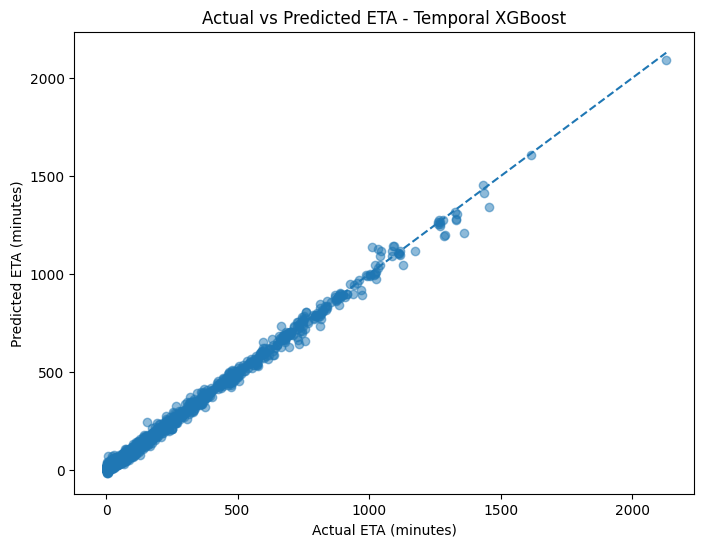

In [144]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_time,
    y_pred_time,
    alpha=0.5
)

# Perfect prediction line
min_value = min(y_test_time.min(), y_pred_time.min())
max_value = max(y_test_time.max(), y_pred_time.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual ETA (minutes)")
plt.ylabel("Predicted ETA (minutes)")
plt.title("Actual vs Predicted ETA - Temporal XGBoost")

plt.show()

In [145]:
# Check feature names for target/future actual information

suspicious_features = [
    feature for feature in feature_names_time
    if (
        "target_station_actual" in feature
        or "target_station_arrival_delay" in feature
        or "actual_arrival" in feature
        or "actual_departure" in feature
    )
]

print("Suspicious features found:", len(suspicious_features))

if len(suspicious_features) == 0:
    print("✅ No target/future actual leakage features found.")
else:
    print("⚠️ Suspicious features:")
    print(suspicious_features)

Suspicious features found: 0
✅ No target/future actual leakage features found.


In [146]:
import joblib

model_bundle = {
    "model": xgb_time,
    "encoder": encoder_time,
    "numeric_cols": numeric_cols_time,
    "categorical_cols": categorical_cols_time,
    "feature_names": feature_names_time
}

joblib.dump(
    model_bundle,
    "eta_xgboost_model_bundle.pkl"
)

print("✅ ETA model bundle saved successfully!")

✅ ETA model bundle saved successfully!


In [147]:
import joblib

# Load saved model bundle
loaded_bundle = joblib.load("eta_xgboost_model_bundle.pkl")

# Extract components
loaded_model = loaded_bundle["model"]
loaded_encoder = loaded_bundle["encoder"]
loaded_numeric_cols = loaded_bundle["numeric_cols"]
loaded_categorical_cols = loaded_bundle["categorical_cols"]
loaded_feature_names = loaded_bundle["feature_names"]

print("✅ Model loaded successfully!")
print("Number of features:", len(loaded_feature_names))
print("Numeric features:", len(loaded_numeric_cols))
print("Categorical features:", len(loaded_categorical_cols))

✅ Model loaded successfully!
Number of features: 399
Numeric features: 90
Categorical features: 27


In [148]:
# Take one future test row
sample = test_time.iloc[[0]].copy()

# Remove columns not used by model
sample_model = sample.drop(columns=drop_cols)

# Separate numerical and categorical
sample_num = sample_model[loaded_numeric_cols].to_numpy()

sample_cat = loaded_encoder.transform(
    sample_model[loaded_categorical_cols]
)

# Combine
sample_final = np.hstack([
    sample_num,
    sample_cat
])

# Prediction
sample_prediction = loaded_model.predict(sample_final)[0]

print("Actual ETA    :", y_test_time.iloc[0], "minutes")
print("Predicted ETA :", round(sample_prediction, 2), "minutes")
print(
    "Absolute Error:",
    round(abs(y_test_time.iloc[0] - sample_prediction), 2),
    "minutes"
)

Actual ETA    : 8.9 minutes
Predicted ETA : 12.67 minutes
Absolute Error: 3.77 minutes


In [149]:
def predict_eta(input_row):
    """
    input_row: pandas DataFrame containing one model-ready row
    """

    # Numerical features
    input_num = input_row[loaded_numeric_cols].to_numpy()

    # Categorical features
    input_cat = loaded_encoder.transform(
        input_row[loaded_categorical_cols]
    )

    # Combine numerical + categorical
    input_final = np.hstack([
        input_num,
        input_cat
    ])

    # Predict ETA
    prediction = loaded_model.predict(input_final)[0]

    return prediction


# Test with one existing test row
sample_input = test_time.iloc[[0]].drop(columns=drop_cols)

predicted_eta = predict_eta(sample_input)

print("Predicted ETA:", round(predicted_eta, 2), "minutes")

Predicted ETA: 12.67 minutes


In [150]:
def format_eta(minutes):
    minutes = round(minutes)

    hours = minutes // 60
    remaining_minutes = minutes % 60

    if hours > 0:
        return f"{hours} hours {remaining_minutes} minutes"
    else:
        return f"{remaining_minutes} minutes"


# Test
print("Predicted ETA:", format_eta(predicted_eta))

Predicted ETA: 13 minutes


In [151]:
print("========== NUMERICAL FEATURES ==========")

for i, col in enumerate(loaded_numeric_cols, 1):
    print(i, col)

print("\n========== CATEGORICAL FEATURES ==========")

for i, col in enumerate(loaded_categorical_cols, 1):
    print(i, col)

========== NUMERICAL FEATURES ==========
1 train_number
2 is_special_train
3 is_weekend
4 current_hour
5 current_month
6 is_night_time
7 source_station_latitude
8 source_station_longitude
9 previous_station_latitude
10 previous_station_longitude
11 current_station_latitude
12 current_station_longitude
13 target_station_latitude
14 target_station_longitude
15 destination_station_latitude
16 destination_station_longitude
17 current_train_latitude
18 current_train_longitude
19 current_station_is_junction
20 current_station_route_count
21 target_station_is_junction
22 target_station_route_count
23 station_sequence_number
24 total_station_count
25 remaining_station_count
26 distance_from_source_km
27 distance_travelled_km
28 distance_previous_to_current_km
29 distance_current_to_target_km
30 remaining_distance_km
31 total_route_distance_km
32 route_progress_percentage
33 scheduled_halt_duration_minutes
34 scheduled_segment_travel_time_minutes
35 scheduled_remaining_travel_time_minutes
36 cu

In [152]:
# Take one existing row as a template
user_input = test_time.iloc[[0]].copy()

# Remove target and unused columns
user_input = user_input.drop(columns=drop_cols)

print("Template created!")
print("Input shape:", user_input.shape)

Template created!
Input shape: (1, 117)


In [153]:
user_input["train_number"] = 12345
user_input["current_train_speed_kmph"] = 55
user_input["current_train_delay_minutes"] = 10
user_input["remaining_distance_km"] = 250

In [154]:
# Show all numerical features
for i, col in enumerate(loaded_numeric_cols, 1):
    print(f"{i}. {col}")

1. train_number
2. is_special_train
3. is_weekend
4. current_hour
5. current_month
6. is_night_time
7. source_station_latitude
8. source_station_longitude
9. previous_station_latitude
10. previous_station_longitude
11. current_station_latitude
12. current_station_longitude
13. target_station_latitude
14. target_station_longitude
15. destination_station_latitude
16. destination_station_longitude
17. current_train_latitude
18. current_train_longitude
19. current_station_is_junction
20. current_station_route_count
21. target_station_is_junction
22. target_station_route_count
23. station_sequence_number
24. total_station_count
25. remaining_station_count
26. distance_from_source_km
27. distance_travelled_km
28. distance_previous_to_current_km
29. distance_current_to_target_km
30. remaining_distance_km
31. total_route_distance_km
32. route_progress_percentage
33. scheduled_halt_duration_minutes
34. scheduled_segment_travel_time_minutes
35. scheduled_remaining_travel_time_minutes
36. current

In [155]:
print("Total unique trains:", df_fe["train_number"].nunique())

print("\nSample trains:")
print(
    df_fe[
        ["train_number", "train_name", "train_type"]
    ]
    .drop_duplicates()
    .head(20)
)

Total unique trains: 37

Sample trains:
    train_number                  train_name    train_type
0          12951     Mumbai Rajdhani Express      Rajdhani
1          22439        Vande Bharat Express  Vande Bharat
2          12302  New Delhi Rajdhani Express      Rajdhani
4          12029     Swarna Shatabdi Express      Shatabdi
5          12123                Deccan Queen     Superfast
6          12724           Telangana Express     Superfast
7          12615         Grand Trunk Express     Superfast
8          12621          Tamil Nadu Express     Superfast
9          18645               Hatia Express       Express
10         58101            Howrah Passenger     Passenger
11         12952  New Delhi Rajdhani Express      Rajdhani
12         58201           Passenger Special     Passenger
15         12622          Tamil Nadu Express     Superfast
16         12839         Howrah Chennai Mail       Express
18         12141            Patalkot Express       Express
21         12801

In [156]:
# Choose one train from the dataset
selected_train = 12951

# Get route information for this train
train_route = (
    df_fe[df_fe["train_number"] == selected_train]
    [
        [
            "train_number",
            "train_name",
            "source_station_name",
            "previous_station_name",
            "current_station_name",
            "target_station_name",
            "destination_station_name",
            "station_sequence_number",
            "total_station_count",
            "remaining_station_count"
        ]
    ]
    .drop_duplicates()
    .sort_values("station_sequence_number")
)

print("Route information:")
display(train_route.head(20))

Route information:


,train_number,train_name,source_station_name,previous_station_name,current_station_name,target_station_name,destination_station_name,station_sequence_number,total_station_count,remaining_station_count
0,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Itarsi Junction,Mumbai CSMT,2,12,10
44,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Kalyan Junction,Mumbai CSMT,2,12,10
609,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Mumbai CSMT,Mumbai CSMT,2,12,10
295,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Gwalior,Mumbai CSMT,2,12,10
1373,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Bhusaval Junction,Mumbai CSMT,2,12,10
811,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Agra Cantt,Mumbai CSMT,2,12,10
5276,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Manmad Junction,Mumbai CSMT,2,12,10
2404,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Nashik Road,Mumbai CSMT,2,12,10
7304,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Bhopal Junction,Mumbai CSMT,2,12,10
4475,12951,Mumbai Rajdhani Express,New Delhi,New Delhi,Mathura Junction,Jhansi Junction,Mumbai CSMT,2,12,10


In [157]:
# Select train
selected_train = 12951

train_data = df_fe[
    df_fe["train_number"] == selected_train
].copy()

print("Train:", selected_train)
print("Train name:", train_data["train_name"].iloc[0])

print("\nAvailable Current → Target combinations:")

routes = (
    train_data[
        ["current_station_name", "target_station_name"]
    ]
    .drop_duplicates()
    .sort_values(
        ["current_station_name", "target_station_name"]
    )
)

display(routes.head(30))

Train: 12951
Train name: Mumbai Rajdhani Express

Available Current → Target combinations:


,current_station_name,target_station_name
522,Agra Cantt,Bhopal Junction
3400,Agra Cantt,Bhusaval Junction
3657,Agra Cantt,Itarsi Junction
9681,Agra Cantt,Jhansi Junction
853,Agra Cantt,Kalyan Junction
4432,Agra Cantt,Manmad Junction
1984,Agra Cantt,Nashik Road
3057,Bhopal Junction,Bhusaval Junction
3250,Bhopal Junction,Itarsi Junction
4331,Bhopal Junction,Kalyan Junction


In [158]:


selected_train = 12951
selected_current = "Gwalior"
selected_target = "Bhopal Junction"

# Test data me selected train + route search
matching_rows = test_time[
    (test_time["train_number"] == selected_train) &
    (test_time["current_station_name"] == selected_current) &
    (test_time["target_station_name"] == selected_target)
].copy()

print("Train:", selected_train)
print("Current Station:", selected_current)
print("Target Station:", selected_target)
print("Matching test rows:", len(matching_rows))

if len(matching_rows) > 0:

    # First matching row
    user_input = matching_rows.iloc[[0]].copy()

    # Actual ETA save kar lo comparison ke liye
    actual_eta = user_input["target_station_eta_minutes"].iloc[0]

    # Target/unwanted columns remove
    user_input_model = user_input.drop(columns=drop_cols)

    # Prediction
    predicted_eta = predict_eta(user_input_model)

    print("\n==============================")
    print("ETA PREDICTION")
    print("==============================")
    print("Train:", selected_train)
    print("Current:", selected_current)
    print("Target:", selected_target)
    print("Actual ETA:", round(actual_eta, 2), "minutes")
    print("Predicted ETA:", round(predicted_eta, 2), "minutes")
    print("Absolute Error:", round(abs(actual_eta - predicted_eta), 2), "minutes")

else:
    print("\nNo matching test record found for this route.")

Train: 12951
Current Station: Gwalior
Target Station: Bhopal Junction
Matching test rows: 0

No matching test record found for this route.


In [159]:
# Train 12951 ke test data me available routes dekho

available_routes = (
    test_time[test_time["train_number"] == 12951]
    [["current_station_name", "target_station_name"]]
    .drop_duplicates()
    .sort_values(
        ["current_station_name", "target_station_name"]
    )
)

print("Available routes for Train 12951 in TEST data:")
display(available_routes)

Available routes for Train 12951 in TEST data:


,current_station_name,target_station_name
8860,Agra Cantt,Itarsi Junction
8953,Agra Cantt,Kalyan Junction
9627,Agra Cantt,Nashik Road
8381,Bhopal Junction,Bhusaval Junction
8594,Bhopal Junction,Itarsi Junction
8634,Bhopal Junction,Kalyan Junction
9158,Bhopal Junction,Mumbai CSMT
9098,Bhopal Junction,Nashik Road
8002,Bhusaval Junction,Kalyan Junction
9480,Bhusaval Junction,Manmad Junction


In [160]:
# ==============================
# VALID ROUTE ETA PREDICTION
# ==============================

selected_train = 12951
selected_current = "Gwalior"
selected_target = "Jhansi Junction"

matching_rows = test_time[
    (test_time["train_number"] == selected_train) &
    (test_time["current_station_name"] == selected_current) &
    (test_time["target_station_name"] == selected_target)
].copy()

print("Train:", selected_train)
print("Current Station:", selected_current)
print("Target Station:", selected_target)
print("Matching rows:", len(matching_rows))

if len(matching_rows) > 0:

    # First available row
    user_input = matching_rows.iloc[[0]].copy()

    # Actual ETA
    actual_eta = user_input["target_station_eta_minutes"].iloc[0]

    # Remove target/unwanted columns
    user_input_model = user_input.drop(columns=drop_cols)

    # Predict
    predicted_eta = predict_eta(user_input_model)

    print("\n==============================")
    print("ETA PREDICTION")
    print("==============================")
    print("Train:", selected_train)
    print("Current:", selected_current)
    print("Target:", selected_target)
    print("Actual ETA:", round(actual_eta, 2), "minutes")
    print("Predicted ETA:", round(predicted_eta, 2), "minutes")
    print(
        "Absolute Error:",
        round(abs(actual_eta - predicted_eta), 2),
        "minutes"
    )

else:
    print("No matching test record found.")

Train: 12951
Current Station: Gwalior
Target Station: Jhansi Junction
Matching rows: 0
No matching test record found.


In [161]:
# Test data me jo routes actually available hain,
# unme se first 10 routes dekho

routes = (
    test_time[
        ["train_number", "train_name",
         "current_station_name", "target_station_name"]
    ]
    .drop_duplicates()
    .head(10)
)

display(routes)

,train_number,train_name,current_station_name,target_station_name
8000,11301,Udyan Express,Bangarapet Junction,KSR Bengaluru City
8001,12615,Grand Trunk Express,Jhansi Junction,Nashik Road
8002,12951,Mumbai Rajdhani Express,Bhusaval Junction,Kalyan Junction
8003,2615,GT Special,Kalyan Junction,Mumbai CSMT
8004,58201,Passenger Special,Alwar,Jaipur Junction
8005,58101,Howrah Passenger,Asansol Junction,Howrah Junction
8006,12615,Grand Trunk Express,Jhansi Junction,Bhopal Junction
8007,12141,Patalkot Express,Agra Cantt,New Delhi
8008,12142,Patalkot Express,Jhansi Junction,Agra Cantt
8009,16021,Kaveri Express,Arakkonam Junction,Krishnarajapuram


In [162]:

selected_train = 12951
selected_current = "Bhusaval Junction"
selected_target = "Kalyan Junction"

matching_rows = test_time[
    (test_time["train_number"] == selected_train) &
    (test_time["current_station_name"] == selected_current) &
    (test_time["target_station_name"] == selected_target)
].copy()

print("Train:", selected_train)
print("Current Station:", selected_current)
print("Target Station:", selected_target)
print("Matching rows:", len(matching_rows))

if len(matching_rows) > 0:

    user_input = matching_rows.iloc[[0]].copy()

    
    actual_eta = user_input["target_station_eta_minutes"].iloc[0]

    
    user_input_model = user_input.drop(columns=drop_cols)

    
    predicted_eta = predict_eta(user_input_model)

    print("\n==============================")
    print("ETA PREDICTION")
    print("==============================")
    print("Train:", selected_train)
    print("Current:", selected_current)
    print("Target:", selected_target)
    print("Actual ETA:", round(actual_eta, 2), "minutes")
    print("Predicted ETA:", round(predicted_eta, 2), "minutes")
    print(
        "Absolute Error:",
        round(abs(actual_eta - predicted_eta), 2),
        "minutes"
    )

else:
    print("No matching test record found.")

Train: 12951
Current Station: Bhusaval Junction
Target Station: Kalyan Junction
Matching rows: 1

ETA PREDICTION
Train: 12951
Current: Bhusaval Junction
Target: Kalyan Junction
Actual ETA: 125.4 minutes
Predicted ETA: 93.28 minutes
Absolute Error: 32.12 minutes


In [163]:
print("Minimum journey date:", df_fe["journey_date"].min())
print("Maximum journey date:", df_fe["journey_date"].max())

Minimum journey date: 2025-09-01 00:00:00
Maximum journey date: 2026-12-31 00:00:00


In [164]:
# Sort data by journey date
df_time = df_fe.sort_values("journey_date").reset_index(drop=True)

# 80% training, 20% testing
split_index = int(len(df_time) * 0.80)

train_time = df_time.iloc[:split_index].copy()
test_time = df_time.iloc[split_index:].copy()

print("Training rows:", train_time.shape)
print("Testing rows:", test_time.shape)

print("\nTraining date range:")
print(train_time["journey_date"].min(), "to", train_time["journey_date"].max())

print("\nTesting date range:")
print(test_time["journey_date"].min(), "to", test_time["journey_date"].max())

Training rows: (8000, 140)
Testing rows: (2000, 140)

Training date range:
2025-09-01 00:00:00 to 2026-09-25 00:00:00

Testing date range:
2026-09-25 00:00:00 to 2026-12-31 00:00:00


In [165]:

target_col = "target_station_eta_minutes"


drop_cols = [
    target_col,
    "target_station_actual_arrival_date",
    "target_station_actual_arrival_time",
    "target_station_arrival_delay_minutes",

   
    "journey_date",
    "journey_start_time",
    "current_time",
    "previous_station_scheduled_arrival_date",
    "previous_station_scheduled_arrival_time",
    "previous_station_scheduled_departure_date",
    "previous_station_scheduled_departure_time",
    "current_station_scheduled_arrival_date",
    "current_station_scheduled_arrival_time",
    "current_station_scheduled_departure_date",
    "current_station_scheduled_departure_time",
    "target_station_scheduled_arrival_date",
    "target_station_scheduled_arrival_time",
    "target_station_scheduled_departure_date",
    "target_station_scheduled_departure_time",

    
    "previous_station_actual_arrival_date",
    "previous_station_actual_arrival_time",
    "previous_station_actual_departure_date",
    "previous_station_actual_departure_time"
]


drop_cols = [col for col in drop_cols if col in train_time.columns]


X_train_time = train_time.drop(columns=drop_cols)
y_train_time = train_time[target_col]

X_test_time = test_time.drop(columns=drop_cols)
y_test_time = test_time[target_col]

print("X_train shape:", X_train_time.shape)
print("X_test shape:", X_test_time.shape)
print("y_train shape:", y_train_time.shape)
print("y_test shape:", y_test_time.shape)

X_train shape: (8000, 117)
X_test shape: (2000, 117)
y_train shape: (8000,)
y_test shape: (2000,)


In [166]:
from sklearn.preprocessing import OneHotEncoder
import numpy as np


numeric_cols_time = X_train_time.select_dtypes(include=np.number).columns.tolist()
categorical_cols_time = X_train_time.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", len(numeric_cols_time))
print("Categorical columns:", len(categorical_cols_time))


encoder_time = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


X_train_cat_time = encoder_time.fit_transform(
    X_train_time[categorical_cols_time]
)


X_test_cat_time = encoder_time.transform(
    X_test_time[categorical_cols_time]
)

print("Encoded train categorical shape:", X_train_cat_time.shape)
print("Encoded test categorical shape:", X_test_cat_time.shape)

Numerical columns: 90
Categorical columns: 27


C:\Users\SHANU KUSHWAHA\AppData\Local\Temp\ipykernel_15544\1438439723.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_time = X_train_time.select_dtypes(include="object").columns.tolist()


Encoded train categorical shape: (8000, 309)
Encoded test categorical shape: (2000, 309)


In [167]:

X_train_num_time = X_train_time[numeric_cols_time].values
X_test_num_time = X_test_time[numeric_cols_time].values


X_train_final_time = np.hstack([
    X_train_num_time,
    X_train_cat_time
])

X_test_final_time = np.hstack([
    X_test_num_time,
    X_test_cat_time
])

print("Final temporal train shape:", X_train_final_time.shape)
print("Final temporal test shape:", X_test_final_time.shape)

Final temporal train shape: (8000, 399)
Final temporal test shape: (2000, 399)


In [168]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


xgb_time = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


xgb_time.fit(X_train_final_time, y_train_time)


y_pred_time = xgb_time.predict(X_test_final_time)


mae_time = mean_absolute_error(y_test_time, y_pred_time)
rmse_time = np.sqrt(mean_squared_error(y_test_time, y_pred_time))
r2_time = r2_score(y_test_time, y_pred_time)

print("Temporal XGBoost Results")
print("========================")
print("MAE :", round(mae_time, 2), "minutes")
print("RMSE:", round(rmse_time, 2), "minutes")
print("R²  :", round(r2_time, 4))

Temporal XGBoost Results
MAE : 10.79 minutes
RMSE: 16.34 minutes
R²  : 0.9962


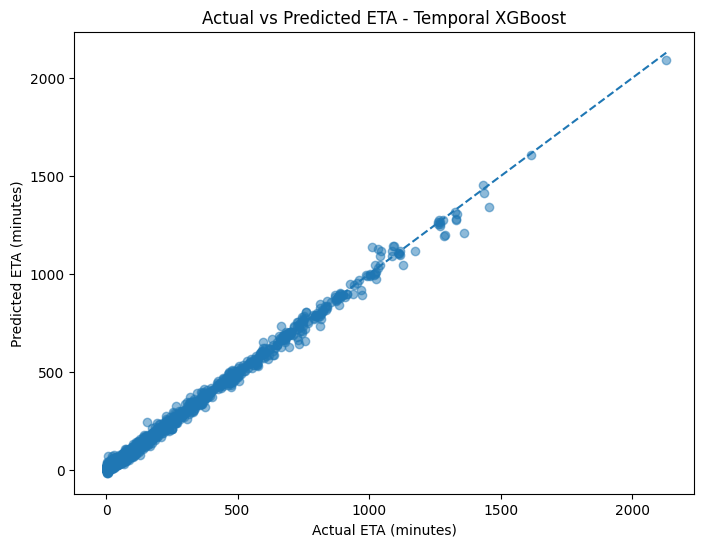

In [169]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test_time, y_pred_time, alpha=0.5)

# Perfect prediction line
min_val = min(y_test_time.min(), y_pred_time.min())
max_val = max(y_test_time.max(), y_pred_time.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual ETA (minutes)")
plt.ylabel("Predicted ETA (minutes)")
plt.title("Actual vs Predicted ETA - Temporal XGBoost")

plt.show()

In [170]:
import numpy as np
import pandas as pd

error_time = y_test_time - y_pred_time
absolute_error_time = np.abs(error_time)

print("Mean Absolute Error:", round(absolute_error_time.mean(), 2), "minutes")
print("Maximum Error:", round(absolute_error_time.max(), 2), "minutes")
print("90th Percentile Error:", round(np.percentile(absolute_error_time, 90), 2), "minutes")
print("95th Percentile Error:", round(np.percentile(absolute_error_time, 95), 2), "minutes")

Mean Absolute Error: 10.79 minutes
Maximum Error: 150.19 minutes
90th Percentile Error: 24.18 minutes
95th Percentile Error: 31.8 minutes


In [171]:


error_df = pd.DataFrame({
    "Actual_ETA": y_test_time.values,
    "Predicted_ETA": y_pred_time,
    "Absolute_Error": absolute_error_time
})


worst_cases = error_df.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

print("Top 10 Worst Predictions:")
display(worst_cases)

Top 10 Worst Predictions:


,Actual_ETA,Predicted_ETA,Absolute_Error
9410,1359.7,1209.508545,150.191455
9695,1010.0,1137.342896,127.342896
8787,1454.9,1341.434082,113.465918
8012,757.4,660.546448,96.853552
8995,1032.8,1126.229370,93.429370
9489,1285.7,1192.486328,93.213672
9015,734.7,642.340210,92.359790
8713,156.7,247.718430,91.018430
9830,1289.2,1200.528076,88.671924
9373,1128.9,1046.429443,82.470557


In [172]:

worst_indices = worst_cases.index

important_cols = [
    "train_number",
    "train_name",
    "current_station_name",
    "target_station_name",
    "current_train_delay_minutes",
    "remaining_distance_km",
    "remaining_station_count",
    "current_train_speed_kmph",
    "scheduled_remaining_travel_time_minutes",
    "scheduled_segment_travel_time_minutes",
    "segment_historical_average_travel_time_minutes",
    "train_historical_average_speed_kmph",
    "train_historical_average_delay_minutes"
]


available_cols = [
    col for col in important_cols
    if col in test_time.columns
]

worst_details = test_time.loc[worst_indices, available_cols].copy()


worst_details["Actual_ETA"] = y_test_time.loc[worst_indices].values
worst_details["Predicted_ETA"] = y_pred_time[
    y_test_time.index.get_indexer(worst_indices)
]

worst_details["Absolute_Error"] = abs(
    worst_details["Actual_ETA"] -
    worst_details["Predicted_ETA"]
)

display(
    worst_details.sort_values(
        "Absolute_Error",
        ascending=False
    )
)

,train_number,train_name,current_station_name,target_station_name,current_train_delay_minutes,remaining_distance_km,remaining_station_count,current_train_speed_kmph,scheduled_remaining_travel_time_minutes,scheduled_segment_travel_time_minutes,segment_historical_average_travel_time_minutes,train_historical_average_speed_kmph,train_historical_average_delay_minutes,Actual_ETA,Predicted_ETA,Absolute_Error
9410,2615,GT Special,Agra Cantt,Mumbai CSMT,24.6,1213.99,9,37.3,1688.2,64.0,1286.1,51.9,32.3,1359.7,1209.508545,150.191455
9695,2615,GT Special,Mathura Junction,Manmad Junction,10.2,600.15,10,53.6,1435.4,179.0,1174.3,51.9,32.3,1010.0,1137.342896,127.342896
8787,58101,Howrah Passenger,Prayagraj Junction,Howrah Junction,34.2,858.49,5,34.8,1537.0,376.8,1028.0,33.4,39.4,1454.9,1341.434082,113.465918
8012,18645,Hatia Express,Prayagraj Junction,Asansol Junction,-3.7,627.79,5,51.5,807.5,261.8,684.1,46.7,16.9,757.4,660.546448,96.853552
8995,2615,GT Special,Mathura Junction,Manmad Junction,15.6,462.99,10,22.7,1435.4,179.0,1174.3,51.9,32.3,1032.8,1126.229370,93.429370
9489,12840,Chennai Howrah Mail,Kharagpur Junction,Vijayawada Junction,24.6,1102.71,4,50.5,1331.9,158.6,1189.6,46.6,22.8,1285.7,1192.486328,93.213672
9015,2951,Mumbai Rajdhani Special,Jhansi Junction,Bhusaval Junction,8.5,639.04,7,60.6,811.8,120.0,720.7,47.7,30.2,734.7,642.340210,92.359790
8713,12952,New Delhi Rajdhani Express,Mathura Junction,Itarsi Junction,1.6,438.67,10,25.4,600.1,126.3,663.3,65.0,14.0,156.7,247.718430,91.018430
9830,2615,GT Special,Mathura Junction,Nashik Road,21.7,1099.76,10,56.4,1544.8,179.0,1209.2,51.9,32.3,1289.2,1200.528076,88.671924
9373,12621,Tamil Nadu Express,Gwalior,Kalyan Junction,6.3,1239.04,8,76.3,1130.5,109.4,1188.8,66.1,22.1,1128.9,1046.429443,82.470557


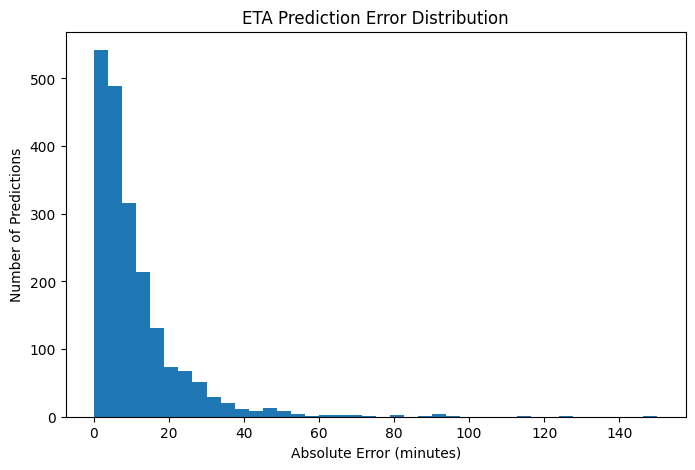

In [173]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(absolute_error_time, bins=40)

plt.xlabel("Absolute Error (minutes)")
plt.ylabel("Number of Predictions")
plt.title("ETA Prediction Error Distribution")

plt.show()

In [174]:

sample_predictions = pd.DataFrame({
    "Actual_ETA": y_test_time.values,
    "Predicted_ETA": y_pred_time,
    "Absolute_Error": absolute_error_time
})


sample_predictions = sample_predictions.sample(
    10, random_state=42
).sort_index()

display(sample_predictions)

,Actual_ETA,Predicted_ETA,Absolute_Error
8065,695.8,692.014954,3.785046
8353,114.2,114.880928,0.680928
8905,480.9,491.903717,11.003717
8938,8.9,14.646378,5.746378
9273,142.9,133.052872,9.847128
9289,23.9,33.789032,9.889032
9323,238.0,232.656448,5.343552
9333,5.9,16.594170,10.694170
9731,5.3,8.457134,3.157134
9860,7.1,9.004282,1.904282


In [175]:
import joblib


joblib.dump(xgb_time, "eta_xgboost_model.pkl")


joblib.dump(encoder_time, "eta_encoder.pkl")

print("Model and encoder saved successfully!")

Model and encoder saved successfully!


In [176]:
print("Number of model features:", xgb_time.n_features_in_)
print("Number of encoded features:", len(encoder_time.get_feature_names_out()))

print("\nNumeric columns:", len(numeric_cols_time))
print("Categorical columns:", len(categorical_cols_time))

Number of model features: 399
Number of encoded features: 309

Numeric columns: 90
Categorical columns: 27


In [177]:
print("NUMERIC COLUMNS:")
for i, col in enumerate(numeric_cols_time, 1):
    print(i, col)

print("\nCATEGORICAL COLUMNS:")
for i, col in enumerate(categorical_cols_time, 1):
    print(i, col)

NUMERIC COLUMNS:
1 train_number
2 is_special_train
3 is_weekend
4 current_hour
5 current_month
6 is_night_time
7 source_station_latitude
8 source_station_longitude
9 previous_station_latitude
10 previous_station_longitude
11 current_station_latitude
12 current_station_longitude
13 target_station_latitude
14 target_station_longitude
15 destination_station_latitude
16 destination_station_longitude
17 current_train_latitude
18 current_train_longitude
19 current_station_is_junction
20 current_station_route_count
21 target_station_is_junction
22 target_station_route_count
23 station_sequence_number
24 total_station_count
25 remaining_station_count
26 distance_from_source_km
27 distance_travelled_km
28 distance_previous_to_current_km
29 distance_current_to_target_km
30 remaining_distance_km
31 total_route_distance_km
32 route_progress_percentage
33 scheduled_halt_duration_minutes
34 scheduled_segment_travel_time_minutes
35 scheduled_remaining_travel_time_minutes
36 current_train_speed_kmph
3

In [178]:


sample_index = 0

sample_features = X_test_final_time[sample_index].reshape(1, -1)

predicted_eta = xgb_time.predict(sample_features)[0]
actual_eta = y_test_time.iloc[sample_index]

print("ETA PREDICTION TEST")
print("===================")
print("Actual ETA    :", round(actual_eta, 2), "minutes")
print("Predicted ETA :", round(predicted_eta, 2), "minutes")
print("Absolute Error:", round(abs(actual_eta - predicted_eta), 2), "minutes")

ETA PREDICTION TEST
Actual ETA    : 8.9 minutes
Predicted ETA : 12.67 minutes
Absolute Error: 3.77 minutes


In [179]:
print("Model input features:", xgb_time.n_features_in_)
print("Encoder categorical columns:", len(categorical_cols_time))
print("Numeric columns:", len(numeric_cols_time))
print("Categorical columns:", len(categorical_cols_time))

Model input features: 399
Encoder categorical columns: 27
Numeric columns: 90
Categorical columns: 27


In [180]:
# Take one test row as input template
sample_index = 0

input_row = X_test_time.iloc[sample_index].copy()

print("Input row shape:", input_row.shape)
print("\nSelected input values:")
print(input_row[[
    "train_number",
    "train_name",
    "current_station_name",
    "target_station_name",
    "current_train_delay_minutes",
    "remaining_distance_km",
    "remaining_station_count",
    "current_train_speed_kmph"
]])

Input row shape: (117,)

Selected input values:
train_number                                 11301
train_name                           Udyan Express
current_station_name           Bangarapet Junction
target_station_name             KSR Bengaluru City
current_train_delay_minutes                   36.2
remaining_distance_km                        15.63
remaining_station_count                          2
current_train_speed_kmph                      40.0
Name: 8000, dtype: object


In [181]:
def predict_eta_from_row(input_row):

    # Convert single row into DataFrame
    input_df = input_row.to_frame().T

    # Categorical features encode karo
    input_cat = encoder_time.transform(
        input_df[categorical_cols_time]
    )

    # Numerical features lo
    input_num = input_df[numeric_cols_time].values

    # Numerical + categorical combine karo
    input_final = np.hstack([
        input_num,
        input_cat
    ])

    # ETA prediction
    prediction = xgb_time.predict(input_final)[0]

    return prediction


# Test prediction
predicted_eta = predict_eta_from_row(input_row)

print("Predicted ETA:", round(predicted_eta, 2), "minutes")

Predicted ETA: 12.67 minutes


In [182]:
def user_eta_prediction(
    train_number,
    current_station,
    target_station,
    current_speed,
    current_delay,
    remaining_distance,
    remaining_stations
):
    
    # Dataset ki ek row ko template ke liye use kar rahe hain
    input_row = X_test_time.iloc[0].copy()

    # User ke inputs update karo
    input_row["train_number"] = train_number
    input_row["current_station_name"] = current_station
    input_row["target_station_name"] = target_station
    input_row["current_train_speed_kmph"] = current_speed
    input_row["current_train_delay_minutes"] = current_delay
    input_row["remaining_distance_km"] = remaining_distance
    input_row["remaining_station_count"] = remaining_stations

    # Prediction
    predicted_eta = predict_eta_from_row(input_row)

    print("========== ETA PREDICTION ==========")
    print("Train Number       :", train_number)
    print("Current Station    :", current_station)
    print("Target Station     :", target_station)
    print("Predicted ETA      :", round(predicted_eta, 2), "minutes")
    print("=====================================")

    return predicted_eta

In [183]:
user_eta_prediction(
    train_number=11301,
    current_station="Bangarapet Junction",
    target_station="KSR Bengaluru City",
    current_speed=40.0,
    current_delay=5.0,
    remaining_distance=15.63,
    remaining_stations=2
)

========== ETA PREDICTION ==========
Train Number       : 11301
Current Station    : Bangarapet Junction
Target Station     : KSR Bengaluru City
Predicted ETA      : 12.21 minutes


np.float32(12.209959)

In [184]:
def format_eta(minutes):
    minutes = max(0, float(minutes))
    
    hours = int(minutes // 60)
    mins = int(round(minutes % 60))

    if hours > 0:
        return f"{hours} hr {mins} min"
    else:
        return f"{mins} min"


# Test
predicted_eta = user_eta_prediction(
    train_number=11301,
    current_station="Bangarapet Junction",
    target_station="KSR Bengaluru City",
    current_speed=40.0,
    current_delay=5.0,
    remaining_distance=15.63,
    remaining_stations=2
)

print("ETA in readable format:", format_eta(predicted_eta))

========== ETA PREDICTION ==========
Train Number       : 11301
Current Station    : Bangarapet Junction
Target Station     : KSR Bengaluru City
Predicted ETA      : 12.21 minutes
ETA in readable format: 12 min


In [185]:
import ipywidgets as widgets
from IPython.display import display

train_number_input = widgets.IntText(
    description="Train No:"
)

current_station_input = widgets.Text(
    description="Current:"
)

target_station_input = widgets.Text(
    description="Target:"
)

speed_input = widgets.FloatText(
    description="Speed:"
)

delay_input = widgets.FloatText(
    description="Delay:"
)

distance_input = widgets.FloatText(
    description="Distance:"
)

stations_input = widgets.IntText(
    description="Stations:"
)

predict_button = widgets.Button(
    description="Predict ETA"
)

output = widgets.Output()


def on_predict_clicked(b):
    with output:
        output.clear_output()

        predicted_eta = user_eta_prediction(
            train_number=train_number_input.value,
            current_station=current_station_input.value,
            target_station=target_station_input.value,
            current_speed=speed_input.value,
            current_delay=delay_input.value,
            remaining_distance=distance_input.value,
            remaining_stations=stations_input.value
        )

        print("\nETA:", format_eta(predicted_eta))


predict_button.on_click(on_predict_clicked)

display(
    train_number_input,
    current_station_input,
    target_station_input,
    speed_input,
    delay_input,
    distance_input,
    stations_input,
    predict_button,
    output
)

IntText(value=0, description='Train No:')

Text(value='', description='Current:')

Text(value='', description='Target:')

FloatText(value=0.0, description='Speed:')

FloatText(value=0.0, description='Delay:')

FloatText(value=0.0, description='Distance:')

IntText(value=0, description='Stations:')

Button(description='Predict ETA', style=ButtonStyle())

Output()

In [186]:
import joblib
model_bundle = {
    "model": xgb_time,
    "encoder": encoder_time,
    "numeric_cols": numeric_cols_time,
    "categorical_cols": categorical_cols_time
}

joblib.dump(model_bundle, "eta_prediction_bundle.pkl")

print("ETA model bundle saved successfully!")

ETA model bundle saved successfully!
